# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

**Nội dung notebook:** (1) cài đặt và kiểm thử các hàm cơ bản của CSP; (2) thêm MRV và LCV vào backtracking; (3) thêm Forward Checking; (4) cài đặt Min-Conflicts (hill climbing); (5) thực nghiệm với 3 và 4 màu trên nhiều kích thước n, nhiều đồ thị ngẫu nhiên.

**Môi trường:** Python 3 với `numpy`, `scipy`, `matplotlib`, `pandas` (phiên bản in ở ô bên dưới). Không dùng đường dẫn cá nhân; chạy lại từ đầu bằng *Restart & Run All*. Mọi thí nghiệm đều có seed cố định nên **COUNT, số bước, số lần khởi động lại** lặp lại được; riêng **thời gian chạy** phụ thuộc máy.

In [1]:
import sys, platform, time, math
import numpy as np, scipy, matplotlib, pandas as pd
print("Python", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy", np.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__, "| pandas", pd.__version__)

Python 3.13.16 | Linux x86_64
numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2 | pandas 3.0.5


Vì đồ thị Delaunay là đồ thị phẳng nên theo định lý bốn màu luôn tô được bằng 4 màu, còn 3 màu thì không bảo đảm.

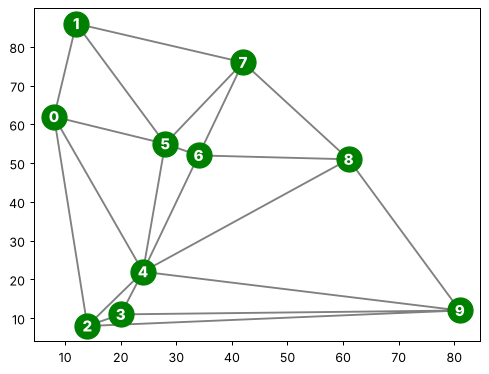

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [3]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32), array([0, 5, 7], dtype=int32), array([0, 3, 4, 9], dtype=int32), array([2, 4, 9], dtype=int32), array([0, 2, 3, 5, 6, 8, 9], dtype=int32), array([0, 1, 4, 6, 7], dtype=int32), array([4, 5, 7, 8], dtype=int32), array([1, 5, 6, 8], dtype=int32), array([4, 6, 7, 9], dtype=int32), array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

## Bài 1. Biểu diễn CSP

Một CSP gồm bộ ba $(X, D, C)$:

- $X$ là tập biến: mỗi đỉnh là một biến (tên dạng chuỗi `'0'`, `'1'`, ...);
- $D$ là tập miền giá trị: mỗi biến có miền là tập màu (4 màu `red, blue, green, orange` hoặc 3 màu);
- $C$ là tập ràng buộc nhị phân *khác nhau*: hai đỉnh kề nhau không được cùng màu. Mỗi cạnh chỉ lưu một lần dưới dạng `(i, j)` với $i < j$.

**Vì sao chỉ tạo ràng buộc cho $i < j$?** Ràng buộc "khác màu" là đối xứng: `color(i) ≠ color(j)` tương đương `color(j) ≠ color(i)`. Danh sách láng giềng của Delaunay liệt kê mỗi cạnh hai lần (một lần ở mỗi đầu), nên nếu không lọc sẽ có ràng buộc trùng lặp, làm tăng gấp đôi số lần kiểm tra mà không thêm thông tin.

**Phép gán đầy đủ và phép gán hợp lệ.** Phép gán *đầy đủ* (complete) là mọi biến đều có giá trị; phép gán *hợp lệ/nhất quán* (consistent) là không vi phạm ràng buộc nào giữa các biến đã gán. Hai khái niệm độc lập: phép gán rỗng thì hợp lệ nhưng chưa đầy đủ; tô mọi đỉnh cùng một màu thì đầy đủ nhưng không hợp lệ. Chỉ phép gán **vừa đầy đủ vừa hợp lệ** mới là *nghiệm* của CSP. Backtracking duy trì phép gán *một phần* hợp lệ rồi mở rộng dần, còn Min-Conflicts duy trì phép gán *đầy đủ* rồi sửa dần các vi phạm.

In [4]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
#domain = ['red', 'blue', 'green']
domains = {}
for v in variables: 
    domains[v] = domain

# create binary constraints
constraints = {}
for i in range(len(neighbors)):
    for j in neighbors[i]:
        if(i<j): constraints[tuple([str(i), str(j)])] = True
constraints = constraints.keys()

csp = {'variables': variables, 'domains': domains, 'constraints': constraints, }
csp

{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], 'domains': {'0': ['red', 'blue', 'green', 'orange'], '1': ['red', 'blue', 'green', 'orange'], '2': ['red', 'blue', 'green', 'orange'], '3': ['red', 'blue', 'green', 'orange'], '4': ['red', 'blue', 'green', 'orange'], '5': ['red', 'blue', 'green', 'orange'], '6': ['red', 'blue', 'green', 'orange'], '7': ['red', 'blue', 'green', 'orange'], '8': ['red', 'blue', 'green', 'orange'], '9': ['red', 'blue', 'green', 'orange']}, 'constraints': dict_keys([('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7'), ('2', '3'), ('2', '4'), ('2', '9'), ('3', '4'), ('3', '9'), ('4', '5'), ('4', '6'), ('4', '8'), ('4', '9'), ('5', '6'), ('5', '7'), ('6', '7'), ('6', '8'), ('7', '8'), ('8', '9')])}

In [5]:
def csp_summary(csp):
    """Tóm tắt một CSP: số biến |X|, kích thước miền |D|, số ràng buộc |C| và bậc trung bình."""
    X, C = csp["variables"], list(csp["constraints"])
    degree = {v: 0 for v in X}
    for a, b in C:
        degree[a] += 1; degree[b] += 1
    return {"|X| (số đỉnh)": len(X), "|D| (số màu)": len(csp["domains"][X[0]]),
            "|C| (số cạnh)": len(C), "bậc trung bình": round(float(np.mean(list(degree.values()))), 2)}

csp4 = csp                                                   # CSP 4 màu (đã tạo ở trên)
csp3 = {"variables": variables, "constraints": constraints,
        "domains": {v: ['red', 'blue', 'green'] for v in variables}}   # cùng đồ thị, chỉ 3 màu
print("4 màu:", csp_summary(csp4))
print("3 màu:", csp_summary(csp3))
print("Vài ràng buộc (i < j):", list(csp4["constraints"])[:6])
print("Đồ thị phẳng tam giác hóa có tối đa 3n-6 =", 3 * n - 6, "cạnh")

4 màu: {'|X| (số đỉnh)': 10, '|D| (số màu)': 4, '|C| (số cạnh)': 21, 'bậc trung bình': 4.2}
3 màu: {'|X| (số đỉnh)': 10, '|D| (số màu)': 3, '|C| (số cạnh)': 21, 'bậc trung bình': 4.2}
Vài ràng buộc (i < j): [('0', '1'), ('0', '2'), ('0', '4'), ('0', '5'), ('1', '5'), ('1', '7')]
Đồ thị phẳng tam giác hóa có tối đa 3n-6 = 24 cạnh


## Check Completeness and Consistency

`assignment` is a dictionary. Assigned variables have an entry with the variable name as the key. `{}` is therefore the empty assignment.

In [6]:
def complete(assignment, csp):
    return(all([v in assignment.keys() for v in csp['variables']])) 

print("complete({}, csp) =", complete({}, csp))

print("complete({...complete list...}, csp) =", 
      complete({'0': 'red', '1': 'red', '2': 'red', '3': 'red', '4': 'red', 
          '5': 'red', '6': 'red', '7': 'red', '8': 'red', '9': 'red'}, csp))

complete({}, csp) = False
complete({...complete list...}, csp) = True


In [7]:
def consistent(assignment, csp):
    for constr in csp['constraints']:
        if(constr[0] in assignment.keys() and constr[1] in assignment.keys()):
            if assignment[constr[0]] == assignment[constr[1]]: return(False)
        
    return(True)
        
print("consistent({}, csp) =", consistent({}, csp))
print("consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) =", 
      consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp))

consistent({}, csp) = True
consistent({'0': 'red', '1': 'red', '2': 'blue'}, csp) = False


## Bài 2. Kiểm tra tính đầy đủ (complete) và nhất quán (consistent)

Một phép gán **đầy đủ** khi mọi biến đã có giá trị; **nhất quán** khi không vi phạm ràng buộc nào giữa các biến *đã gán*. Một **nghiệm** là phép gán vừa đầy đủ vừa nhất quán.

### Kiểm thử hai hàm trên các ca biên

Năm ca bên dưới có đáp án biết trước (phép gán rỗng, một phần hợp lệ, một phần vi phạm, đầy đủ nhưng vi phạm, đầy đủ và hợp lệ). `assert` bảo đảm kết quả thực tế khớp mong đợi; bảng cho thấy cả hai cột trùng nhau.

In [8]:
# Phép gán tham lam (greedy) dùng làm ví dụ "đầy đủ và hợp lệ"
adj_ = {v: [] for v in variables}
for p, q in csp4["constraints"]:
    adj_[p].append(q); adj_[q].append(p)
greedy = {}
for v in variables:
    used = {greedy[u] for u in adj_[v] if u in greedy}
    greedy[v] = next(c for c in csp4["domains"][v] if c not in used)

a, b = list(csp4["constraints"])[0]                  # một cạnh (a, b) bất kỳ
tests = [
    ("T1: phép gán rỗng {}",                                     {},                          False, True),
    ("T2: một phần, hai đỉnh kề khác màu",                       {a: 'red', b: 'blue'},       False, True),
    ("T3: một phần, hai đỉnh kề cùng màu",                       {a: 'red', b: 'red'},        False, False),
    ("T4: đầy đủ nhưng mọi đỉnh cùng 'red'",                     {v: 'red' for v in variables}, True, False),
    ("T5: đầy đủ và hợp lệ (tô tham lam)",                       greedy,                      True,  True),
]
rows = []
for name, asg, exp_c, exp_k in tests:
    got_c, got_k = complete(asg, csp4), consistent(asg, csp4)
    assert got_c == exp_c and got_k == exp_k, name          # kiểm thử tự động
    rows.append({"Ca kiểm thử": name, "complete (mong đợi)": exp_c, "complete (thực tế)": got_c,
                 "consistent (mong đợi)": exp_k, "consistent (thực tế)": got_k})
tests_table = pd.DataFrame(rows)
tests_table

                            Ca kiểm thử  complete (mong đợi)  complete (thực tế)  consistent (mong đợi)  consistent (thực tế)
0                  T1: phép gán rỗng {}                False               False                   True                  True
1    T2: một phần, hai đỉnh kề khác màu                False               False                   True                  True
2    T3: một phần, hai đỉnh kề cùng màu                False               False                  False                 False
3  T4: đầy đủ nhưng mọi đỉnh cùng 'red'                 True                True                  False                 False
4    T5: đầy đủ và hợp lệ (tô tham lam)                 True                True                   True                  True

## Implement Simple Backtracking Search

## Bài 3. Backtracking và thứ tự chọn biến

Phiên bản gốc chọn **biến chưa gán đầu tiên** và thử các màu **theo thứ tự miền**. `COUNT` đếm số lần gọi đệ quy `backtrack`, tức số nút được xét; đây là thước đo hiệu năng chính của backtracking.

In [9]:
# TODO: implement variable ordering. Choose variable with the minimum-remaining-values (MRV)
def select_unassigned_var(assignment, csp):
    if(complete(assignment, csp)): return(None)
    
    return(csp['variables'][np.where([not v in assignment.keys() for v in csp['variables']])[0][0]])

print("select_unassigned_var({'0': 'red', '1': 'blue'}, csp) =", 
     select_unassigned_var({'0': 'red', '1': 'blue'}, csp))

select_unassigned_var({'0': 'red', '1': 'blue'}, csp) = 2


In [10]:
# I use a global variable to turn on verbose mode in the recursion
#VERBOSE = True
VERBOSE = False
COUNT = 0

# returns None for failure
def backtrack_search(csp):
    global COUNT
    COUNT = 0
    
    assignment = backtrack({}, csp)
    
    print(f"Checked nodes: {COUNT}")
    
    return assignment

def backtrack(assignment, csp):
    global VERBOSE, COUNT
    
    COUNT += 1
    
    if complete(assignment, csp): 
        return assignment
    
    var = select_unassigned_var(assignment, csp)
    
    # TODO: implement value ordering. Use the least-constraining-value heuristic. 
    # for val in order_domain(assignment, var, csp)
    for val in csp['domains'][var]:
        assignment[var] = val
        
        if VERBOSE: print(f"Checking: {assignment}")
        
        if consistent(assignment, csp):
            
            #TODO: add inference for early failing (forward checking, )
            # if inference_fails(assignment, csp): return(None)
            result = backtrack(assignment, csp)
            if not result is None:
                    return(result)
                
        del assignment[var]
        
    if VERBOSE: print(f"Backtracking")
    return(None) 

## Run Backtracking Search on the Random Problem

In [11]:
%time res = backtrack_search(csp)
display(res)

Checked nodes: 11
{'0': 'red', '1': 'blue', '2': 'blue', '3': 'red', '4': 'green', '5': 'orange', '6': 'red', '7': 'green', '8': 'blue', '9': 'orange'}
Wall time: 0.2 ms


[None]

Plot the resulting coloring

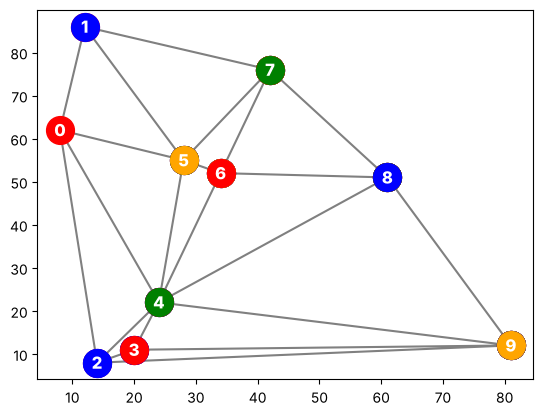

In [ ]:
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")

for i in range(len(points)):
        plt.plot(points[i:,0], points[i:,1], 'o', color = list(res.values())[i], markersize = 20)
        plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

Vẽ kết quả tô màu (đã sửa lỗi của bản gốc: màu mỗi đỉnh lấy theo **tên biến**, không theo thứ tự các giá trị trong từ điển, nên vẫn đúng khi dùng MRV hoặc khi không có nghiệm).

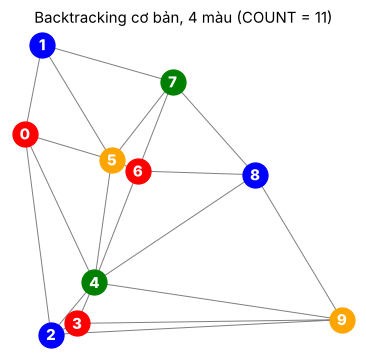

In [12]:
def plot_coloring(points, tri, assignment, title=""):
    """Vẽ đồ thị tam giác hóa với màu của từng đỉnh lấy từ assignment (khóa là tên biến dạng chuỗi)."""
    plt.figure(figsize=(5, 4.6))
    plt.triplot(points[:, 0], points[:, 1], tri.simplices, color="gray", linewidth=0.8)
    for i in range(len(points)):
        plt.plot(points[i, 0], points[i, 1], 'o', color=assignment[str(i)], markersize=20)
        plt.annotate(i, points[i, :], color='white', fontsize="large", weight='heavy',
                     horizontalalignment='center', verticalalignment='center')
    plt.title(title); plt.axis("off"); plt.show()

plot_coloring(points, tri, res, f"Backtracking cơ bản, 4 màu (COUNT = {COUNT})")

In [13]:
# Quan sát thứ tự biến của phiên bản gốc: luôn chọn biến chưa gán đầu tiên (0, 1, 2, ...)
print("Thứ tự gán của phiên bản gốc:", list(res.keys()))
print("Kiểm tra nghiệm: complete =", complete(res, csp4), "| consistent =", consistent(res, csp4))
# Số màu thực sự được dùng
print("Các màu được dùng:", sorted(set(res.values())))

Thứ tự gán của phiên bản gốc: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
Kiểm tra nghiệm: complete = True | consistent = True
Các màu được dùng: ['blue', 'green', 'orange', 'red']


## Assignment

Implement the following graph coloring algorithms:

* Add variable and value ordering to the implementation.
* Add forward checking to the implementation.
* Implement hill climbing local search with the min-conflicts heuristic.

Try to color graphs of several sizes with 3 and 4 colors. For each $n$, generate several random instances, and try to make n as large as you can manage. On average, how many constraints (edges) do your map coloring instances have for each $n$? Report the performance of each search algorithm as a function of $n$. For both variants of backtracking search, you can characterize performance in terms of the number of variable assignments attempted. For hill climbing search, report the number of uphill moves and random restarts required in order to reach a solution. Of course, you can also report raw running times as a function of $n$.

### Cài đặt MRV và LCV

- **MRV (Minimum Remaining Values):** chọn biến chưa gán có *ít giá trị hợp lệ nhất* (hòa thì lấy biến đứng đầu). Biến càng ít lựa chọn càng dễ thất bại, nên phát hiện sớm sẽ cắt được nhánh lớn.
- **LCV (Least Constraining Value):** với biến đã chọn, thử trước màu làm các láng giềng chưa gán *mất ít lựa chọn nhất*.

Hàm `solve_basic` giữ nguyên định nghĩa COUNT của bản gốc và thêm tham số `mrv`, `lcv`. Ô kiểm tra cuối chứng minh khi tắt cả hai thì COUNT và nghiệm **trùng khớp bản gốc**. Tham số `limit` đặt trần số nút; kết quả `'limit'` nghĩa là *hết giới hạn* (chưa kết luận), khác với `'unsat'` là *đã duyệt hết và chứng minh vô nghiệm*.

In [14]:
def build_adjacency(csp):
    """Danh sách kề của đồ thị, dựng từ tập ràng buộc nhị phân (đưa thêm vào csp['adj'])."""
    adj = {v: [] for v in csp["variables"]}
    for p, q in csp["constraints"]:
        adj[p].append(q); adj[q].append(p)
    return adj

csp4["adj"] = build_adjacency(csp4); csp3["adj"] = build_adjacency(csp3)

def legal_values(var, assignment, csp, domains=None):
    """Các giá trị của var còn hợp lệ: nằm trong miền và không trùng màu với láng giềng đã gán."""
    dom = domains[var] if domains is not None else csp["domains"][var]
    used = {assignment[u] for u in csp["adj"][var] if u in assignment}
    return [c for c in dom if c not in used]

def select_var_mrv(assignment, csp, domains=None):
    """Minimum Remaining Values: chọn biến chưa gán có ÍT giá trị hợp lệ nhất (hòa thì lấy biến đầu tiên)."""
    unassigned = [v for v in csp["variables"] if v not in assignment]
    if not unassigned: return None
    return min(unassigned, key=lambda v: len(legal_values(v, assignment, csp, domains)))

def order_values_lcv(var, assignment, csp, domains=None):
    """Least Constraining Value: thử trước màu làm mất ít lựa chọn nhất của các láng giềng chưa gán."""
    def eliminated(c):
        return sum(1 for u in csp["adj"][var]
                   if u not in assignment and c in legal_values(u, assignment, csp, domains))
    return sorted(legal_values(var, assignment, csp, domains), key=eliminated)

class SearchLimit(Exception):
    """Dừng tìm kiếm khi vượt quá số nút cho phép (phân biệt 'hết giới hạn' với 'chứng minh vô nghiệm')."""

def solve_basic(csp, mrv=False, lcv=False, limit=200000):
    """Backtracking; mrv/lcv bật chọn biến / thứ tự giá trị.
    Trả về (nghiệm hoặc None, COUNT, trạng thái) với trạng thái in {'solved', 'unsat', 'limit'}.
    COUNT = số nút được kiểm tra (mỗi lần gọi đệ quy sau khi phép gán còn hợp lệ), cùng định nghĩa với backtrack() gốc."""
    adj, variables = csp["adj"], csp["variables"]
    assignment, count = {}, [0]

    def rec():
        count[0] += 1
        if count[0] > limit: raise SearchLimit
        if len(assignment) == len(variables): return True
        var = select_var_mrv(assignment, csp) if mrv else next(v for v in variables if v not in assignment)
        if lcv:   values = order_values_lcv(var, assignment, csp)
        else:     values = csp["domains"][var]
        for val in values:
            if any(assignment.get(u) == val for u in adj[var]):      # vi phạm ràng buộc -> bỏ giá trị này
                continue
            assignment[var] = val
            if rec(): return True
            del assignment[var]
        return False

    try:
        ok = rec()
        return (dict(assignment) if ok else None), count[0], ("solved" if ok else "unsat")
    except SearchLimit:
        return None, count[0], "limit"

# Kiểm tra tính đúng: bản mới (không MRV/LCV) phải cho CÙNG COUNT với backtrack() gốc
res0 = backtrack_search(csp4)
r_basic = solve_basic(csp4)
print("COUNT gốc =", COUNT, "| COUNT solve_basic =", r_basic[1], "| cùng nghiệm:", r_basic[0] == res0)

Checked nodes: 11
COUNT gốc = 11 | COUNT solve_basic = 11 | cùng nghiệm: True


Trên đồ thị gốc ($n = 10$, seed 1111) bài toán quá dễ: cả bốn cấu hình đều tìm nghiệm với cùng COUNT = 11 (tức không phải quay lui lần nào), nên chưa thể phân biệt các heuristic.

In [15]:
rows = []
for name, kw in [("Gốc (biến đầu tiên, giá trị theo thứ tự miền)", {}),
                 ("MRV", {"mrv": True}),
                 ("LCV", {"lcv": True}),
                 ("MRV + LCV", {"mrv": True, "lcv": True})]:
    t0 = time.perf_counter()
    asg, cnt, status = solve_basic(csp4, **kw)
    dt = 1e3 * (time.perf_counter() - t0)
    rows.append({"Phiên bản": name, "Kết quả": status, "COUNT": cnt, "Thời gian (ms)": round(dt, 2),
                 "Hợp lệ": consistent(asg, csp4) and complete(asg, csp4)})
compare_bt = pd.DataFrame(rows)
compare_bt

                                       Phiên bản Kết quả  COUNT  Thời gian (ms)  Hợp lệ
0  Gốc (biến đầu tiên, giá trị theo thứ tự miền)  solved     11            0.03    True
1                                            MRV  solved     11            0.07    True
2                                            LCV  solved     11            0.07    True
3                                      MRV + LCV  solved     11            0.09    True

Để thấy sự khác biệt ta thử một đồ thị lớn hơn ($n = 60$, seed 42). Cần các hàm sinh đồ thị/CSP tổng quát, được định nghĩa ngay dưới đây và dùng lại ở các phần sau.

In [16]:
def make_graph(n, seed):
    """Sinh n điểm ngẫu nhiên trong [0,100)^2, tam giác hóa Delaunay, trả về (points, tri, neighbors)."""
    rng = np.random.RandomState(seed)
    pts = np.unique(rng.randint(100, size=(n, 2)), axis=0)          # bỏ điểm trùng
    while len(pts) < n:
        pts = np.unique(np.vstack([pts, rng.randint(100, size=(1, 2))]), axis=0)
    pts = pts[np.argsort(pts[:, 0], kind="stable"), :]
    tri_ = Delaunay(pts)
    indptr_, indices_ = tri_.vertex_neighbor_vertices
    nbrs = [np.sort(indices_[indptr_[k]:indptr_[k + 1]]) for k in range(len(indptr_) - 1)]
    return pts, tri_, nbrs

def make_csp(nbrs, colors):
    """Tạo csp giống ở trên (chỉ cạnh i < j) và thêm danh sách kề 'adj'."""
    X = [str(v) for v in range(len(nbrs))]
    C = {}
    for i in range(len(nbrs)):
        for j in nbrs[i]:
            if i < j: C[(str(i), str(j))] = True
    out = {"variables": X, "domains": {v: list(colors) for v in X}, "constraints": C.keys()}
    out["adj"] = build_adjacency(out)
    return out

COLORS4 = ['red', 'blue', 'green', 'orange']
COLORS3 = COLORS4[:3]

In [17]:
# Cùng so sánh trên một đồ thị lớn hơn (n = 60, seed 42) để thấy rõ tác dụng của MRV/LCV
pts60, tri60, nb60 = make_graph(60, 42)
csp60 = make_csp(nb60, ['red', 'blue', 'green', 'orange'])
rows = []
for name, kw in [("Gốc", {}), ("MRV", {"mrv": True}), ("LCV", {"lcv": True}), ("MRV + LCV", {"mrv": True, "lcv": True})]:
    t0 = time.perf_counter()
    asg, cnt, status = solve_basic(csp60, **kw)
    rows.append({"Phiên bản": name, "Kết quả": status, "COUNT": cnt,
                 "Thời gian (ms)": round(1e3 * (time.perf_counter() - t0), 2)})
compare_bt60 = pd.DataFrame(rows)
compare_bt60

   Phiên bản Kết quả  COUNT  Thời gian (ms)
0        Gốc  solved    107            0.28
1        MRV  solved    240            3.12
2        LCV  solved    529            3.16
3  MRV + LCV  solved     80            1.82

**Nhận xét.** Trên *một* đồ thị $n = 60$, MRV riêng lẻ (COUNT 240) và LCV riêng lẻ (529) thậm chí **tệ hơn** bản gốc (107), chỉ có MRV + LCV (80) tốt hơn. Heuristic không đảm bảo thắng trên từng ví dụ: kết quả của một đồ thị bị chi phối bởi may rủi. Đồng thời mỗi nút của MRV/LCV tốn nhiều thời gian hơn vì phải tính lại số giá trị hợp lệ. Vì vậy ở phần thực nghiệm bên dưới ta so sánh trên **nhiều đồ thị** và lấy trung bình.

## Bài 4. Forward Checking, Min-Conflicts và thực nghiệm

### Forward Checking

Sau mỗi phép gán `var = val`, ta **loại `val` khỏi miền của các láng giềng chưa gán**. Nếu một miền trở thành rỗng thì thất bại ngay (không cần đi tiếp). Khi quay lui phải **khôi phục** đúng các miền đã bị sửa (`undo_forward_check`). Cài đặt dùng bản sao `domains` thu hẹp dần, và có thể kết hợp tuỳ chọn với MRV, LCV (khi đó các heuristic nhìn miền đã thu hẹp).

In [18]:
def forward_check(var, val, assignment, csp, domains):
    """Sau khi gán var = val: loại val khỏi miền các láng giềng CHƯA gán.
    Trả về (ok, removed): ok = False nếu có miền rỗng; removed lưu các miền đã sửa để hoàn tác."""
    removed = []
    for u in csp["adj"][var]:
        if u not in assignment and val in domains[u]:
            domains[u].remove(val); removed.append(u)
            if not domains[u]:
                return False, removed
    return True, removed

def undo_forward_check(val, domains, removed):
    """Hoàn tác khi quay lui: trả màu val về miền các đỉnh đã bị sửa."""
    for u in removed:
        domains[u].append(val)

def solve_fc(csp, mrv=False, lcv=False, limit=200000):
    """Backtracking + Forward Checking (+ MRV/LCV tùy chọn, dùng miền đã được thu hẹp)."""
    variables = csp["variables"]
    domains = {v: list(csp["domains"][v]) for v in variables}       # bản sao miền, bị thu hẹp dần
    assignment, count = {}, [0]

    def rec():
        count[0] += 1
        if count[0] > limit: raise SearchLimit
        if len(assignment) == len(variables): return True
        var = select_var_mrv(assignment, csp, domains) if mrv else next(v for v in variables if v not in assignment)
        values = order_values_lcv(var, assignment, csp, domains) if lcv else list(domains[var])
        for val in values:
            assignment[var] = val
            ok, removed = forward_check(var, val, assignment, csp, domains)
            if ok and rec(): return True
            undo_forward_check(val, domains, removed)              # hoàn tác miền khi quay lui
            del assignment[var]
        return False

    try:
        ok = rec()
        return (dict(assignment) if ok else None), count[0], ("solved" if ok else "unsat")
    except SearchLimit:
        return None, count[0], "limit"

# Kiểm tra nhanh: nghiệm của FC phải hợp lệ và đầy đủ
for kw in [{}, {"mrv": True}, {"mrv": True, "lcv": True}]:
    asg, cnt, st = solve_fc(csp4, **kw)
    print(f"FC {kw}: {st}, COUNT = {cnt}, hợp lệ = {complete(asg, csp4) and consistent(asg, csp4)}")

FC {}: solved, COUNT = 11, hợp lệ = True
FC {'mrv': True}: solved, COUNT = 11, hợp lệ = True
FC {'mrv': True, 'lcv': True}: solved, COUNT = 11, hợp lệ = True


Cả ba cấu hình Forward Checking trên đồ thị gốc đều cho nghiệm hợp lệ, đầy đủ với COUNT = 11, khớp với kết quả backtracking. Sự khác biệt về hiệu quả sẽ thể hiện ở phần thực nghiệm.

### Min-Conflicts (hill climbing cục bộ)

Khác với backtracking (xây dựng phép gán *một phần*), tìm kiếm cục bộ làm việc trên phép gán **đầy đủ** và sửa dần:

1. khởi tạo mỗi đỉnh một màu ngẫu nhiên;
2. mỗi bước chọn ngẫu nhiên một đỉnh đang vi phạm và đổi sang màu **ít xung đột nhất** với láng giềng (hòa thì chọn ngẫu nhiên);
3. dừng khi không còn xung đột; nếu sau `max_steps` bước chưa xong thì **khởi động lại ngẫu nhiên** (tối đa `max_restarts` lần).

Ta ghi lại: tổng số bước, số **nước đi cải thiện** (làm giảm số xung đột của đỉnh, tức "uphill" theo đề bài) và số lần khởi động lại.

In [19]:
def min_conflicts(csp, rng, max_steps, max_restarts):
    """Hill climbing cục bộ với heuristic min-conflicts.
    Khởi tạo phép gán ĐẦY ĐỦ ngẫu nhiên; mỗi bước: chọn ngẫu nhiên một đỉnh đang vi phạm rồi đổi sang màu
    ít xung đột nhất (hòa thì chọn ngẫu nhiên). Nếu sau max_steps bước vẫn chưa xong -> khởi động lại.
    Trả về (nghiệm|None, tổng số bước, số nước đi LÀM GIẢM xung đột (uphill), số lần khởi động lại, thành công)."""
    adj, variables = csp["adj"], csp["variables"]
    colors = csp["domains"][variables[0]]
    steps = uphill = 0
    for restart in range(max_restarts):
        a = {v: colors[rng.randint(len(colors))] for v in variables}
        for _ in range(max_steps):
            conflicted = [v for v in variables if any(a[u] == a[v] for u in adj[v])]
            if not conflicted:
                return a, steps, uphill, restart, True
            v = conflicted[rng.randint(len(conflicted))]
            cnt = {c: sum(1 for u in adj[v] if a[u] == c) for c in colors}
            best = min(cnt.values()); choices = [c for c in colors if cnt[c] == best]
            new = choices[rng.randint(len(choices))]
            if cnt[new] < cnt[a[v]]: uphill += 1
            a[v] = new; steps += 1
        conflicted = [v for v in variables if any(a[u] == a[v] for u in adj[v])]
        if not conflicted: return a, steps, uphill, restart, True
    return None, steps, uphill, max_restarts, False

# Ví dụ trên đồ thị n = 10 (4 màu)
rng_demo = np.random.RandomState(0)
asg, steps, up, restarts, ok = min_conflicts(csp4, rng_demo, max_steps=100, max_restarts=10)
print(f"thành công = {ok}, bước = {steps}, nước đi cải thiện = {up}, khởi động lại = {restarts}, hợp lệ = {consistent(asg, csp4) and complete(asg, csp4)}")

thành công = True, bước = 6, nước đi cải thiện = 4, khởi động lại = 0, hợp lệ = True


Trên đồ thị gốc, Min-Conflicts giải được sau 6 bước (4 nước đi cải thiện, không khởi động lại) với nghiệm hợp lệ.

### Thực nghiệm theo kích thước $n$ với 3 và 4 màu

**Thiết lập.** Với mỗi $n$ ta sinh nhiều đồ thị ngẫu nhiên (seed khác nhau) và mọi thuật toán chạy trên **cùng tập đồ thị**. Trần backtracking là 200 000 nút. Các cột: tỉ lệ tìm được nghiệm; tỉ lệ *chứng minh vô nghiệm*; tỉ lệ *hết giới hạn*; COUNT trung bình; thời gian trung bình.

**(a) $n = 10$, 100 đồ thị, 4 màu và 3 màu.** Số cạnh trung bình bằng 21,05 (tối đa $3n-6 = 24$).

In [20]:
def run_bt_experiment(n, colors, n_graphs, base_seed, configs, limit=200000):
    """Chạy các cấu hình backtracking trên n_graphs đồ thị ngẫu nhiên (seed = base_seed + g) CÙNG dữ liệu cho mọi cấu hình."""
    graphs = [make_csp(make_graph(n, base_seed + g)[2], colors) for g in range(n_graphs)]
    edges = np.mean([len(list(g["constraints"])) for g in graphs])
    rows = []
    for name, (fn, kw) in configs.items():
        stats = {"solved": 0, "unsat": 0, "limit": 0}; counts, times = [], []
        for g in graphs:
            t0 = time.perf_counter()
            asg, cnt, st = fn(g, limit=limit, **kw)
            times.append(time.perf_counter() - t0); counts.append(cnt); stats[st] += 1
            if st == "solved": assert complete(asg, g) and consistent(asg, g)
        rows.append({"Thuật toán": name, "n": n, "Số màu": len(colors),
                     "Tìm được nghiệm (%)": 100 * stats["solved"] / n_graphs,
                     "Chứng minh vô nghiệm (%)": 100 * stats["unsat"] / n_graphs,
                     "Hết giới hạn (%)": 100 * stats["limit"] / n_graphs,
                     "COUNT TB": np.mean(counts), "Thời gian TB (ms)": 1e3 * np.mean(times)})
    return pd.DataFrame(rows), edges

BT_CONFIGS = {
    "Backtracking":              (solve_basic, {}),
    "MRV + Backtracking":        (solve_basic, {"mrv": True}),
    "Forward Checking":          (solve_fc,    {}),
    "MRV + Forward Checking":    (solve_fc,    {"mrv": True}),
    "MRV + LCV + Forward Checking": (solve_fc, {"mrv": True, "lcv": True}),
}
tab_n10_4, e10 = run_bt_experiment(10, COLORS4, 100, 1000, BT_CONFIGS)
tab_n10_3, _   = run_bt_experiment(10, COLORS3, 100, 1000, BT_CONFIGS)
print(f"Số cạnh trung bình (n = 10): {e10:.1f}")
pd.concat([tab_n10_4, tab_n10_3]).round(2)

Số cạnh trung bình (n = 10): 21.1


                     Thuật toán   n  Số màu  Tìm được nghiệm (%)  Chứng minh vô nghiệm (%)  Hết giới hạn (%)  COUNT TB  Thời gian TB (ms)
0                  Backtracking  10       4                100.0                       0.0               0.0     11.59               0.02
1            MRV + Backtracking  10       4                100.0                       0.0               0.0     11.30               0.06
2              Forward Checking  10       4                100.0                       0.0               0.0     11.20               0.02
3        MRV + Forward Checking  10       4                100.0                       0.0               0.0     11.18               0.05
4  MRV + LCV + Forward Checking  10       4                100.0                       0.0               0.0     11.17               0.12
0                  Backtracking  10       3                  5.0                      95.0               0.0     47.27               0.14
1            MRV + Backtracking  1

**Nhận xét.** Với 4 màu, mọi thuật toán đều giải 100 % với COUNT gần như bằng 11 = $n + 1$ (hầu như không quay lui), nên các heuristic không có tác dụng đáng kể ở $n$ nhỏ.

Với 3 màu, **chỉ 5 % đồ thị có nghiệm**; 95 % được backtracking *chứng minh là vô nghiệm* (không phải hết giới hạn). Lý do: đồ thị Delaunay là tam giác hóa, và đồ thị tam giác hóa phẳng chỉ tô được 3 màu khi mọi đỉnh trong có bậc chẵn, điều rất hiếm với điểm ngẫu nhiên. Ở các bài toán vô nghiệm này, các heuristic cho thấy tác dụng rõ: COUNT giảm từ 47,3 (Backtracking) xuống 32,0 (MRV), 29,9 (FC) và 26,3 (MRV + FC), tức khoảng 44 % số nút.

**(b) Tăng $n$ lên 10, 20, 50, 100, 200 (20 đồ thị mỗi cỡ, 4 màu).** Số cạnh trung bình và so sánh với giới hạn $3n-6$ được in ở đầu kết quả.

In [21]:
SIZES = [10, 20, 50, 100, 200]
scale_rows, edge_rows = [], []
for n_ in SIZES:
    tab, e_ = run_bt_experiment(n_, COLORS4, 20, 2000 + n_, BT_CONFIGS, limit=200000)
    scale_rows.append(tab); edge_rows.append({"n": n_, "Số cạnh TB": round(e_, 1), "Cạnh / n": round(e_ / n_, 2), "3n-6": 3 * n_ - 6})
tab_scale = pd.concat(scale_rows).reset_index(drop=True)
tab_edges = pd.DataFrame(edge_rows)
display_cols = ["Thuật toán", "n", "Tìm được nghiệm (%)", "Hết giới hạn (%)", "COUNT TB", "Thời gian TB (ms)"]
print(tab_edges.to_string(index=False))
tab_scale[display_cols].round(2)

  n  Số cạnh TB  Cạnh / n  3n-6
 10        21.4      2.14    24
 20        49.8      2.49    54
 50       137.1      2.74   144
100       284.3      2.84   294
200       582.6      2.91   594


                      Thuật toán    n  Tìm được nghiệm (%)  Hết giới hạn (%)  COUNT TB  Thời gian TB (ms)
0                   Backtracking   10                100.0               0.0     11.80               0.06
1             MRV + Backtracking   10                100.0               0.0     11.30               0.20
2               Forward Checking   10                100.0               0.0     11.40               0.03
3         MRV + Forward Checking   10                100.0               0.0     11.20               0.08
4   MRV + LCV + Forward Checking   10                100.0               0.0     11.20               0.15
5                   Backtracking   20                100.0               0.0     35.20               0.11
6             MRV + Backtracking   20                100.0               0.0     24.05               0.21
7               Forward Checking   20                100.0               0.0     25.60               0.06
8         MRV + Forward Checking   20         

**Nhận xét.**

- Số cạnh tăng gần tuyến tính theo $n$ và luôn nhỏ hơn $3n-6$; tỉ lệ cạnh/đỉnh tiến dần tới 3 (từ 2,14 ở $n = 10$ lên 2,91 ở $n = 200$).
- Backtracking cơ bản bùng nổ: COUNT trung bình tăng từ 11,8 ($n = 10$) lên 1 649 ($n = 100$) và 37 027 ($n = 200$), thời gian ≈ 250 ms, và **10 % đồ thị ở $n = 200$ vượt trần 200 000 nút**.
- Forward Checking đơn thuần giảm mạnh (517 nút ở $n = 100$) nhưng vẫn có 5 % hết giới hạn ở $n = 200$.
- MRV là heuristic hiệu quả nhất: MRV + Backtracking chỉ 114,6 nút ở $n = 100$ và 496 nút ở $n = 200$ (giải 100 %); MRV + FC còn 443,8; **MRV + LCV + FC chỉ 241,8 nút**, thời gian ≈ 15–20 ms, nhanh nhất ở $n = 200$.
- Ở $n$ nhỏ ($\le 50$) MRV/LCV có COUNT thấp hơn nhưng **thời gian lại cao hơn** Backtracking trơn, vì chi phí tính heuristic trên mỗi nút. Heuristic chỉ có lợi về thời gian khi bài toán đủ lớn.

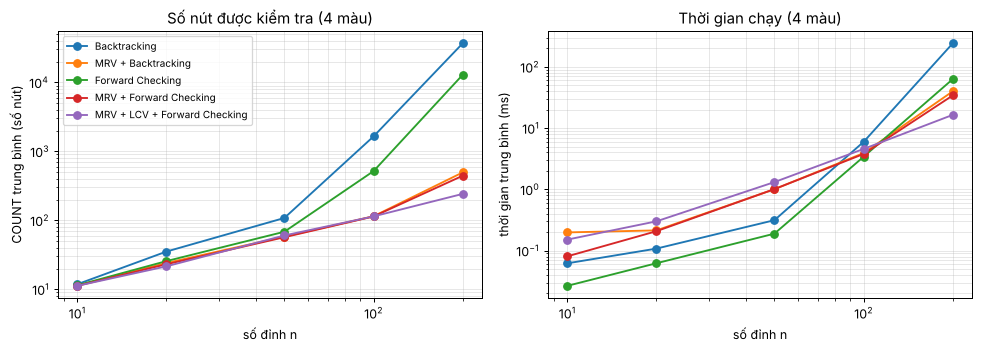

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in BT_CONFIGS:
    sub = tab_scale[tab_scale["Thuật toán"] == name]
    axes[0].loglog(sub["n"], sub["COUNT TB"], "o-", label=name)
    axes[1].loglog(sub["n"], sub["Thời gian TB (ms)"], "o-", label=name)
axes[0].set_xlabel("số đỉnh n"); axes[0].set_ylabel("COUNT trung bình (số nút)"); axes[0].set_title("Số nút được kiểm tra (4 màu)")
axes[1].set_xlabel("số đỉnh n"); axes[1].set_ylabel("thời gian trung bình (ms)"); axes[1].set_title("Thời gian chạy (4 màu)")
for ax in axes: ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Biểu đồ phân tích 1.** Hai đồ thị log-log cho COUNT và thời gian theo $n$. Đường của Backtracking và Forward Checking dốc hơn hẳn các cấu hình có MRV, thể hiện sự tăng trưởng nhanh hơn.

In [23]:
# Độ ổn định theo seed: lặp lại thí nghiệm n = 100 với 5 nhóm seed khác nhau, mỗi nhóm 20 đồ thị
rows = []
for k in range(5):
    tab, _ = run_bt_experiment(100, COLORS4, 20, 5000 + 100 * k, {"Backtracking": BT_CONFIGS["Backtracking"],
                                                                  "MRV + Forward Checking": BT_CONFIGS["MRV + Forward Checking"]})
    tab["nhóm seed"] = 5000 + 100 * k
    rows.append(tab)
seed_tab = pd.concat(rows)
tab_seed_stability = seed_tab.groupby("Thuật toán")[["Tìm được nghiệm (%)", "COUNT TB", "Thời gian TB (ms)"]].agg(["mean", "std"]).round(2)
tab_seed_stability.columns = [f"{a} ({b})" for a, b in tab_seed_stability.columns]   # làm phẳng tên cột
tab_seed_stability

                        Tìm được nghiệm (%) (mean)  Tìm được nghiệm (%) (std)  COUNT TB (mean)  COUNT TB (std)  Thời gian TB (ms) (mean)  Thời gian TB (ms) (std)
Thuật toán                                                                                                                                                       
Backtracking                                  99.0                       2.24          3640.14         4838.52                     17.89                    24.09
MRV + Forward Checking                       100.0                       0.00           121.32           23.50                      4.97                     0.88

**Độ ổn định theo seed.** Lặp lại thí nghiệm $n = 100$ trên 5 nhóm seed khác nhau: MRV + FC luôn giải 100 % với COUNT ≈ 121 (độ lệch chuẩn 23,5), còn Backtracking cơ bản có COUNT trung bình ≈ 3 640 với độ lệch chuẩn ≈ 4 839, tức **biến thiên rất lớn** (phân bố có đuôi nặng: vài đồ thị khó kéo trung bình lên). Do đó nên đánh giá trên nhiều đồ thị chứ không dựa vào một ví dụ.

In [24]:
def run_mc_experiment(n, colors, n_graphs, base_seed, steps_factor=10, max_restarts=10, graphs=None):
    graphs = graphs or [make_csp(make_graph(n, base_seed + g)[2], colors) for g in range(n_graphs)]
    rng = np.random.RandomState(base_seed)
    ok = []; steps = []; ups = []; rst = []; times = []
    for g in graphs:
        t0 = time.perf_counter()
        asg, s, u, r, success = min_conflicts(g, rng, max_steps=steps_factor * n, max_restarts=max_restarts)
        times.append(time.perf_counter() - t0); ok.append(success); steps.append(s); ups.append(u); rst.append(r)
        if success: assert complete(asg, g) and consistent(asg, g)
    return {"Thuật toán": "Min-Conflicts", "n": n, "Số màu": len(colors), "Số đồ thị": len(graphs),
            "Tìm được nghiệm (%)": 100 * np.mean(ok), "Số bước TB": np.mean(steps),
            "Nước đi cải thiện TB": np.mean(ups), "Khởi động lại TB": np.mean(rst), "Thời gian TB (ms)": 1e3 * np.mean(times)}

mc_rows = []
for k_, cols_ in ((4, COLORS4), (3, COLORS3)):
    for n_ in SIZES:
        mc_rows.append(run_mc_experiment(n_, cols_, 20, 2000 + n_))
tab_mc = pd.DataFrame(mc_rows)
tab_mc.round(2)

      Thuật toán    n  Số màu  Số đồ thị  Tìm được nghiệm (%)  Số bước TB  Nước đi cải thiện TB  Khởi động lại TB  Thời gian TB (ms)
0  Min-Conflicts   10       4         20                100.0       12.05                  3.85              0.00               0.17
1  Min-Conflicts   20       4         20                100.0       49.40                 10.25              0.00               1.07
2  Min-Conflicts   50       4         20                100.0      374.50                 35.50              0.45              13.87
3  Min-Conflicts  100       4         20                100.0     1338.35                 97.95              0.90              95.85
4  Min-Conflicts  200       4         20                 75.0     9591.45                545.20              4.40            1150.21
5  Min-Conflicts   10       3         20                  5.0      950.40                 39.60              9.50              11.51
6  Min-Conflicts   20       3         20                  0.0     200

**Min-Conflicts.** Với 4 màu, Min-Conflicts giải 100 % đến $n = 100$ nhưng chỉ còn 75 % ở $n = 200$ khi ngân sách là `10n` bước mỗi lần và tối đa 10 lần khởi động lại. Số bước tăng nhanh: 12 ($n = 10$) → 1 338 ($n = 100$) → 9 591 ($n = 200$), kèm 4,4 lần khởi động lại trung bình ở $n = 200$; thời gian ≈ 1,2 s, **chậm hơn** MRV + FC (≈ 30–40 ms) nhiều lần ở cùng cỡ. Cần lưu ý số "nước đi cải thiện" (545 ở $n = 200$) chỉ là một phần nhỏ so với tổng số bước vì nhiều bước là đi ngang trên cao nguyên.

Với 3 màu, Min-Conflicts gần như luôn thất bại (5 % ở $n = 10$, 0 % từ $n = 20$) nhưng **điều này không phản ánh điểm yếu của thuật toán**, vì hầu hết các đồ thị 3 màu vốn vô nghiệm; Min-Conflicts không chứng minh được vô nghiệm, nó chỉ dùng hết ngân sách rồi dừng. Để đánh giá công bằng, ta lọc ra các đồ thị có nghiệm 3 màu (do backtracking đã chứng minh) và chạy lại ở ô tiếp theo.

In [25]:
# 3 màu: nhiều đồ thị VÔ NGHIỆM nên Min-Conflicts thất bại là đúng. Ta lọc ra các đồ thị 3 màu CÓ nghiệm
# (đã được backtracking chứng minh) để đánh giá công bằng khả năng tìm nghiệm của Min-Conflicts.
solvable3 = []
for seed in range(1000, 6000):
    g = make_csp(make_graph(10, seed)[2], COLORS3)
    if solve_fc(g, mrv=True)[2] == "solved": solvable3.append(g)
    if len(solvable3) == 20: break
print(f"Tìm được {len(solvable3)} đồ thị n = 10 có nghiệm 3 màu (duyệt tối đa 5000 đồ thị).")
tab_mc3 = pd.DataFrame([run_mc_experiment(10, COLORS3, len(solvable3), 7, graphs=solvable3, max_restarts=20),
                        run_mc_experiment(10, COLORS3, len(solvable3), 7, graphs=solvable3, max_restarts=100)])
tab_mc3["max restarts"] = [20, 100]
tab_mc3.round(2)

Tìm được 20 đồ thị n = 10 có nghiệm 3 màu (duyệt tối đa 5000 đồ thị).


      Thuật toán   n  Số màu  Số đồ thị  Tìm được nghiệm (%)  Số bước TB  Nước đi cải thiện TB  Khởi động lại TB  Thời gian TB (ms)  max restarts
0  Min-Conflicts  10       3         20                100.0       25.45                   4.8               0.0               0.26            20
1  Min-Conflicts  10       3         20                100.0       25.45                   4.8               0.0               0.25           100

Đồ thị seed 1111 với 3 màu: trạng thái = unsat, COUNT = 28


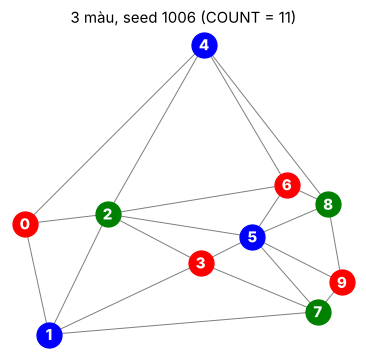

In [26]:
# Minh họa: một đồ thị n = 10 CÓ nghiệm 3 màu và nghiệm do MRV + Forward Checking tìm được
seed3 = next(s for s in range(1000, 6000) if solve_fc(make_csp(make_graph(10, s)[2], COLORS3), mrv=True)[2] == "solved")
p3, t3, nb3 = make_graph(10, seed3)
g3 = make_csp(nb3, COLORS3)
asg3, cnt3, st3 = solve_fc(g3, mrv=True)
plot_coloring(p3, t3, asg3, f"3 màu, seed {seed3} (COUNT = {cnt3})")
# Đồ thị ban đầu (seed 1111) với 3 màu:
a3, c3, s3 = solve_fc(csp3, mrv=True)
print(f"Đồ thị seed 1111 với 3 màu: trạng thái = {s3}, COUNT = {c3}")

**Nhận xét.** Trên 20 đồ thị $n = 10$ *có nghiệm* 3 màu, Min-Conflicts giải **100 %** với trung bình 25,45 bước và 4,8 nước đi cải thiện, không cần khởi động lại; tăng `max_restarts` từ 20 lên 100 không đổi kết quả. Vậy khi bài toán có nghiệm Min-Conflicts hoạt động tốt; điểm yếu là *không thể kết luận vô nghiệm*. Đồ thị gốc (seed 1111) với 3 màu là một ví dụ vô nghiệm: backtracking chứng minh điều đó chỉ sau 28 nút.

## Tổng kết

| Thuật toán | Ưu điểm | Hạn chế |
|---|---|---|
| Backtracking cơ bản | Đơn giản, đầy đủ (chứng minh được vô nghiệm) | COUNT bùng nổ khi $n$ lớn, rất nhạy với đồ thị |
| + MRV | Giảm COUNT mạnh nhất, ổn định | Tốn thêm thời gian trên mỗi nút (chậm hơn ở $n$ nhỏ) |
| + LCV | Có lợi khi đi cùng MRV và FC | Riêng lẻ có thể không cải thiện |
| + Forward Checking | Phát hiện sớm miền rỗng, giảm nút | Cần khôi phục miền khi quay lui |
| MRV + LCV + FC | Tốt nhất ở $n = 200$ (≈ 242 nút, ≈ 15–20 ms) | Cài đặt phức tạp hơn |
| Min-Conflicts | Giải nhanh khi nhiều nghiệm và $n$ vừa phải; bộ nhớ nhỏ | Không chứng minh được vô nghiệm; phụ thuộc ngân sách bước, chậm hơn ở $n = 200$ |

**Kết luận.** Không có thuật toán nào thắng tuyệt đối: nếu cần kết luận chắc chắn (kể cả vô nghiệm) nên dùng backtracking với MRV + FC (+ LCV); nếu chỉ cần tìm nghiệm cho bài toán rất lớn, ít ràng buộc chặt thì local search là lựa chọn nhẹ về bộ nhớ nhưng phải chấp nhận không có đảm bảo. Với bài toán này, số màu quyết định độ khó nhiều hơn kích thước: với 3 màu đa số đồ thị vô nghiệm, với 4 màu hầu như luôn có nghiệm và dễ tìm.